# Bird bridge manifest and taxon crosswalk EDA

This notebook explores the two products of the CUB-200-2011/iNaturalist bridge:

- `bird_bridge_manifest.csv`: one row per source image, with harmonized taxon identifiers and source-specific metadata.
- `cub_inaturalist_taxon_crosswalk.csv`: one row per canonical taxon, describing whether and how CUB and iNaturalist taxa correspond.

The analysis focuses on:

1. schema, completeness, uniqueness, and referential integrity;
2. taxon overlap and match methods;
3. image/class balance across datasets;
4. taxonomy and image-property distributions;
5. CUB split/bounding-box quality and iNaturalist date/geospatial/license coverage.

All analyses are read-only. Missing values in source-specific columns are often **structural** (for example, CUB has bounding boxes while iNaturalist has location/license fields), so completeness is assessed by source where appropriate.

## 1. Setup and input discovery

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_bridge_dir() -> Path:
    # Find the bridge output directory from common notebook launch locations.
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "Bridge Outputs",
        cwd / "Outputs" / "Bridge Outputs",
        cwd / "Notebooks" / "Outputs" / "Bridge Outputs",
        cwd.parent / "Bridge Outputs",
        cwd.parent / "Outputs" / "Bridge Outputs",
    ]
    for candidate in candidates:
        if (
            (candidate / "bird_bridge_manifest.csv").is_file()
            and (candidate / "cub_inaturalist_taxon_crosswalk.csv").is_file()
        ):
            return candidate
    checked = "\n".join(f"- {path}" for path in candidates)
    raise FileNotFoundError(f"Could not find both bridge CSVs. Checked:\n{checked}")


BRIDGE_DIR = find_bridge_dir()
MANIFEST_PATH = BRIDGE_DIR / "bird_bridge_manifest.csv"
CROSSWALK_PATH = BRIDGE_DIR / "cub_inaturalist_taxon_crosswalk.csv"
SUMMARY_PATH = BRIDGE_DIR / "bird_bridge_summary.json"

print(f"Bridge directory: {BRIDGE_DIR}")
print(f"Manifest:  {MANIFEST_PATH.name} ({MANIFEST_PATH.stat().st_size / 1024**2:,.1f} MiB)")
print(f"Crosswalk: {CROSSWALK_PATH.name} ({CROSSWALK_PATH.stat().st_size / 1024**2:,.1f} MiB)")

Bridge directory: C:\Users\Joe\Desktop\ESP_Classifier\esp32_Classifier\Notebooks\Outputs\Bridge Outputs
Manifest:  bird_bridge_manifest.csv (110.1 MiB)
Crosswalk: cub_inaturalist_taxon_crosswalk.csv (0.5 MiB)


## 2. Load the bridge tables

In [2]:
manifest = pd.read_csv(MANIFEST_PATH, low_memory=False)
crosswalk = pd.read_csv(CROSSWALK_PATH, low_memory=False)

# Parse the only date-like source field. Invalid or absent dates become NaT.
manifest["date_parsed"] = pd.to_datetime(manifest["date"], errors="coerce", utc=True)

source_order = ["cub_200_2011", "inaturalist"]
manifest["source_dataset"] = pd.Categorical(
    manifest["source_dataset"], categories=source_order, ordered=True
)

overview = pd.DataFrame(
    {
        "rows": [len(manifest), len(crosswalk)],
        "columns": [manifest.shape[1] - 1, crosswalk.shape[1]],  # excludes derived date_parsed
        "duplicate_full_rows": [manifest.drop(columns="date_parsed").duplicated().sum(), crosswalk.duplicated().sum()],
        "memory_MiB": [manifest.memory_usage(deep=True).sum() / 1024**2, crosswalk.memory_usage(deep=True).sum() / 1024**2],
    },
    index=["manifest", "crosswalk"],
)
display(overview)

if SUMMARY_PATH.is_file():
    with SUMMARY_PATH.open("r", encoding="utf-8") as handle:
        build_summary = json.load(handle)
    print(f"Bridge generated (UTC): {build_summary.get('generated_utc', 'not recorded')}")
    display(pd.Series(build_summary.get("validations", {}), name="passed").to_frame())
else:
    build_summary = {}
    print("Optional bird_bridge_summary.json was not found.")

,rows,columns,duplicate_full_rows,memory_MiB
manifest,86088,70,0,144.597
crosswalk,1507,23,0,0.659


Bridge generated (UTC): 2026-10-06T20:51:36.920189+00:00


,passed
cub_image_count_matches_expected,True
cub_class_count_matches_expected,True
inaturalist_image_count_matches_expected,True
inaturalist_category_count_matches_expected,True
source_manifests_declare_all_files_present,True
dataset_roots_exist,True
photo_roots_exist,True
crosswalk_taxon_ids_are_unique,True
every_cub_class_has_crosswalk_entry,True
every_inaturalist_category_has_crosswalk_entry,True


In [3]:
display(Markdown("### Manifest preview"))
display(manifest.drop(columns="date_parsed").head(3))
display(Markdown("### Crosswalk preview"))
display(crosswalk.head(5))

### Manifest preview

,bridge_image_id,source_dataset,source_image_id,source_annotation_id,source_taxon_id,canonical_taxon_id,match_status,match_method,shared_between_datasets,dataset_root,photos_directory,image_directory,source_relative_path,relative_path,photo_relative_path,absolute_path,file_name,source_file_name,file_exists,file_size_bytes,width_px,height_px,scientific_name,common_name,supercategory,kingdom,phylum,taxonomic_class,order,family,genus,specific_epithet,cub_class_id,cub_class_name,is_training_image,split,bbox_x,bbox_y,bbox_width,bbox_height,bbox_right,bbox_bottom,bbox_area_fraction,bbox_within_image,pixel_count,megapixels,aspect_ratio,orientation,image_format,image_mode,channel_count,estimated_uncompressed_bytes,estimated_compression_ratio,encoded_bits_per_pixel,scan_error,visible_part_count,mturk_part_click_count,mturk_visible_part_click_count,mturk_mean_click_time_seconds,present_attribute_count,inaturalist_category_id,inaturalist_image_dir_name,date,rights_holder,latitude,longitude,location_uncertainty,license_id,license_name,license_url
0,cub:1,cub_200_2011,1,NaN,cub:1,inaturalist:4487,shared_taxon,normalized_common_name,True,E:\Datasets\CUB_200\CUB_200_2011,E:\Datasets\CUB_200\CUB_200_2011\images,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...,001.Black_footed_Albatross/Black_Footed_Albatr...,images/001.Black_footed_Albatross/Black_Footed...,001.Black_footed_Albatross/Black_Footed_Albatr...,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...,Black_Footed_Albatross_0046_18.jpg,001.Black_footed_Albatross/Black_Footed_Albatr...,True,110211,500,335,Phoebastria nigripes,Black-footed Albatross,Birds,Animalia,Chordata,Aves,Procellariiformes,Diomedeidae,Phoebastria,nigripes,1.000,001.Black_footed_Albatross,0.000,test,60.000,27.000,325.000,304.000,385.000,331.000,0.590,True,"167,500.000",0.168,1.493,landscape,JPEG,RGB,3.000,"502,500.000",4.559,5.264,NaN,6.000,75.000,33.000,4.473,12.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cub:2,cub_200_2011,2,NaN,cub:1,inaturalist:4487,shared_taxon,normalized_common_name,True,E:\Datasets\CUB_200\CUB_200_2011,E:\Datasets\CUB_200\CUB_200_2011\images,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...,001.Black_footed_Albatross/Black_Footed_Albatr...,images/001.Black_footed_Albatross/Black_Footed...,001.Black_footed_Albatross/Black_Footed_Albatr...,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...,Black_Footed_Albatross_0009_34.jpg,001.Black_footed_Albatross/Black_Footed_Albatr...,True,52938,500,336,Phoebastria nigripes,Black-footed Albatross,Birds,Animalia,Chordata,Aves,Procellariiformes,Diomedeidae,Phoebastria,nigripes,1.000,001.Black_footed_Albatross,1.000,train,139.000,30.000,153.000,264.000,292.000,294.000,0.240,True,"168,000.000",0.168,1.488,landscape,JPEG,RGB,3.000,"504,000.000",9.521,2.521,NaN,11.000,75.000,56.000,4.289,27.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cub:3,cub_200_2011,3,NaN,cub:1,inaturalist:4487,shared_taxon,normalized_common_name,True,E:\Datasets\CUB_200\CUB_200_2011,E:\Datasets\CUB_200\CUB_200_2011\images,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...,001.Black_footed_Albatross/Black_Footed_Albatr...,images/001.Black_footed_Albatross/Black_Footed...,001.Black_footed_Albatross/Black_Footed_Albatr...,E:\Datasets\CUB_200\CUB_200_2011\images\001.Bl...,Black_Footed_Albatross_0002_55.jpg,001.Black_footed_Albatross/Black_Footed_Albatr...,True,132473,500,347,Phoebastria nigripes,Black-footed Albatross,Birds,Animalia,Chordata,Aves,Procellariiformes,Diomedeidae,Phoebastria,nigripes,1.000,001.Black_footed_Albatross,0.000,test,14.000,112.000,388.000,186.000,402.000,298.000,0.416,True,"173,500.000",0.173,1.441,landscape,JPEG,RGB,3.000,"520,500.000",3.929,6.108,NaN,11.000,75.000,55.000,4.545,26.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Crosswalk preview

,canonical_taxon_id,match_status,match_method,match_note,shared_between_datasets,cub_class_id,cub_class_name,cub_common_name,cub_image_count,inaturalist_category_id,inaturalist_common_name,inaturalist_image_count,scientific_name,canonical_common_name,supercategory,kingdom,phylum,taxonomic_class,order,family,genus,specific_epithet,inaturalist_image_dir_name
0,inaturalist:4487,shared_taxon,normalized_common_name,NaN,True,1.000,001.Black_footed_Albatross,Black footed Albatross,60,"4,487.000",Black-footed Albatross,50,Phoebastria nigripes,Black-footed Albatross,Birds,Animalia,Chordata,Aves,Procellariiformes,Diomedeidae,Phoebastria,nigripes,04487_Animalia_Chordata_Aves_Procellariiformes...
1,inaturalist:4486,shared_taxon,normalized_common_name,NaN,True,2.000,002.Laysan_Albatross,Laysan Albatross,60,"4,486.000",Laysan Albatross,50,Phoebastria immutabilis,Laysan Albatross,Birds,Animalia,Chordata,Aves,Procellariiformes,Diomedeidae,Phoebastria,immutabilis,04486_Animalia_Chordata_Aves_Procellariiformes...
2,cub:3,cub_only,unmatched,No corresponding category in the iNaturalist m...,False,3.000,003.Sooty_Albatross,Sooty Albatross,58,NaN,NaN,0,NaN,Sooty Albatross,Birds,Animalia,Chordata,Aves,NaN,NaN,NaN,NaN,NaN
3,inaturalist:3586,shared_taxon,normalized_common_name,NaN,True,4.000,004.Groove_billed_Ani,Groove billed Ani,60,"3,586.000",Groove-billed Ani,50,Crotophaga sulcirostris,Groove-billed Ani,Birds,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Crotophaga,sulcirostris,03586_Animalia_Chordata_Aves_Cuculiformes_Cucu...
4,cub:5,cub_only,unmatched,No corresponding category in the iNaturalist m...,False,5.000,005.Crested_Auklet,Crested Auklet,44,NaN,NaN,0,NaN,Crested Auklet,Birds,Animalia,Chordata,Aves,NaN,NaN,NaN,NaN,NaN


## 3. Schema and data-quality checks

The checks below cover primary-key uniqueness, source-specific identifiers, crosswalk coverage, the relationship between match status and the shared flag, recorded file availability, and image dimensions. A failed check is shown explicitly rather than stopping the rest of the EDA.

In [4]:
source_id_duplicates = manifest.duplicated(["source_dataset", "source_image_id"]).sum()
crosswalk_taxa = set(crosswalk["canonical_taxon_id"])
manifest_taxa = set(manifest["canonical_taxon_id"])

quality_checks = pd.Series(
    {
        "manifest bridge_image_id is unique": manifest["bridge_image_id"].is_unique,
        "manifest source + source_image_id is unique": source_id_duplicates == 0,
        "crosswalk canonical_taxon_id is unique": crosswalk["canonical_taxon_id"].is_unique,
        "every manifest taxon is in crosswalk": manifest_taxa <= crosswalk_taxa,
        "every crosswalk taxon has manifest image(s)": crosswalk_taxa <= manifest_taxa,
        "shared flag agrees with match_status (manifest)": manifest["shared_between_datasets"].eq(manifest["match_status"].eq("shared_taxon")).all(),
        "shared flag agrees with match_status (crosswalk)": crosswalk["shared_between_datasets"].eq(crosswalk["match_status"].eq("shared_taxon")).all(),
        "all declared files exist": manifest["file_exists"].fillna(False).all(),
        "width and height are positive": manifest[["width_px", "height_px"]].gt(0).all().all(),
        "no scan errors recorded": manifest["scan_error"].isna().all(),
    },
    name="passed",
).to_frame()
quality_checks["status"] = np.where(quality_checks["passed"], "PASS", "FAIL")
display(quality_checks[["status", "passed"]])

print(f"Manifest taxa absent from crosswalk: {len(manifest_taxa - crosswalk_taxa):,}")
print(f"Crosswalk taxa with no manifest rows: {len(crosswalk_taxa - manifest_taxa):,}")

,status,passed
manifest bridge_image_id is unique,PASS,True
manifest source + source_image_id is unique,PASS,True
crosswalk canonical_taxon_id is unique,PASS,True
every manifest taxon is in crosswalk,PASS,True
every crosswalk taxon has manifest image(s),PASS,True
shared flag agrees with match_status (manifest),PASS,True
shared flag agrees with match_status (crosswalk),PASS,True
all declared files exist,PASS,True
width and height are positive,PASS,True
no scan errors recorded,PASS,True


Manifest taxa absent from crosswalk: 0
Crosswalk taxa with no manifest rows: 0


In [5]:
# Validate image counts stored in the crosswalk against counts recomputed from the manifest.
observed_counts = (
    manifest.groupby(["canonical_taxon_id", "source_dataset"], observed=True)
    .size()
    .unstack(fill_value=0)
    .rename(columns={"cub_200_2011": "observed_cub", "inaturalist": "observed_inaturalist"})
)
for expected in ["observed_cub", "observed_inaturalist"]:
    if expected not in observed_counts:
        observed_counts[expected] = 0

count_audit = crosswalk[
    ["canonical_taxon_id", "cub_image_count", "inaturalist_image_count"]
].merge(observed_counts.reset_index(), on="canonical_taxon_id", how="left")
count_audit[["observed_cub", "observed_inaturalist"]] = count_audit[
    ["observed_cub", "observed_inaturalist"]
].fillna(0)
count_audit["cub_count_agrees"] = count_audit["cub_image_count"].eq(count_audit["observed_cub"])
count_audit["inaturalist_count_agrees"] = count_audit["inaturalist_image_count"].eq(count_audit["observed_inaturalist"])

display(
    pd.DataFrame(
        {
            "check": ["CUB image counts", "iNaturalist image counts"],
            "mismatched_taxa": [
                (~count_audit["cub_count_agrees"]).sum(),
                (~count_audit["inaturalist_count_agrees"]).sum(),
            ],
        }
    )
)
display(count_audit.loc[~(count_audit["cub_count_agrees"] & count_audit["inaturalist_count_agrees"])].head(20))

,check,mismatched_taxa
0,CUB image counts,0
1,iNaturalist image counts,0


,canonical_taxon_id,cub_image_count,inaturalist_image_count,observed_cub,observed_inaturalist,cub_count_agrees,inaturalist_count_agrees


In [6]:
# Missingness is reported by source because many fields intentionally apply to only one dataset.
key_fields = [
    "canonical_taxon_id", "scientific_name", "common_name", "order", "family", "genus",
    "width_px", "height_px", "file_size_bytes", "split", "bbox_area_fraction",
    "date", "latitude", "longitude", "license_name",
]
missing_by_source = (
    manifest.groupby("source_dataset", observed=True)[key_fields]
    .agg(lambda column: column.isna().mean() * 100)
    .T
)
missing_by_source.columns = [f"{column}_missing_pct" for column in missing_by_source.columns]
display(missing_by_source.style.format("{:.1f}%").background_gradient(cmap="Reds", vmin=0, vmax=100))

,cub_200_2011_missing_pct,inaturalist_missing_pct
canonical_taxon_id,0.0%,0.0%
scientific_name,9.6%,0.0%
common_name,0.0%,0.0%
order,9.6%,0.0%
family,9.6%,0.0%
genus,9.6%,0.0%
width_px,0.0%,0.0%
height_px,0.0%,0.0%
file_size_bytes,0.0%,0.0%
split,0.0%,100.0%


## 4. Dataset composition and bridge overlap

### Image rows by bridge status and source

source_dataset,cub_200_2011,inaturalist,All
match_status,,,
cub_only,1131,0,1131
inaturalist_only,0,65350,65350
shared_taxon,10657,8950,19607
All,11788,74300,86088


### Canonical taxa by bridge status

shared_between_datasets,False,True,All
match_status,,,
cub_only,21,0,21
inaturalist_only,1307,0,1307
shared_taxon,0,179,179
All,1328,179,1507


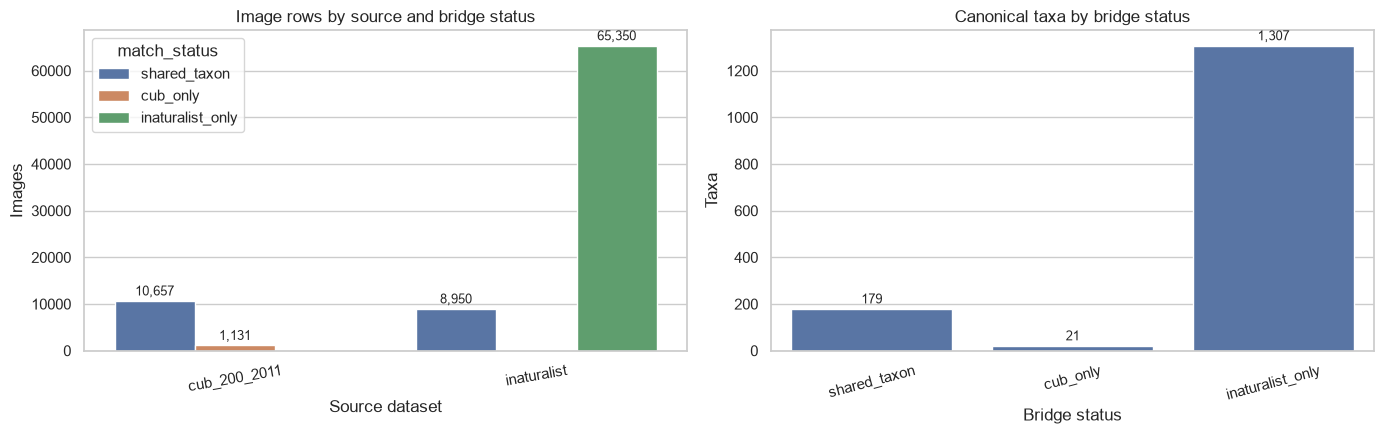

In [7]:
image_composition = pd.crosstab(
    manifest["match_status"], manifest["source_dataset"], margins=True
)
taxon_composition = pd.crosstab(
    crosswalk["match_status"], crosswalk["shared_between_datasets"], margins=True
)
display(Markdown("### Image rows by bridge status and source"))
display(image_composition)
display(Markdown("### Canonical taxa by bridge status"))
display(taxon_composition)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.countplot(data=manifest, x="source_dataset", hue="match_status", ax=axes[0])
axes[0].set(title="Image rows by source and bridge status", xlabel="Source dataset", ylabel="Images")
axes[0].tick_params(axis="x", rotation=10)
sns.countplot(data=crosswalk, x="match_status", order=["shared_taxon", "cub_only", "inaturalist_only"], ax=axes[1], color="#4c72b0")
axes[1].set(title="Canonical taxa by bridge status", xlabel="Bridge status", ylabel="Taxa")
axes[1].tick_params(axis="x", rotation=15)
for axis in axes:
    for container in axis.containers:
        axis.bar_label(container, fmt="{:,.0f}", padding=2, fontsize=9)
plt.tight_layout()
plt.show()

match_method,curated_alias,no_cub_counterpart,normalized_common_name,unmatched,All
match_status,,,,,
cub_only,0,0,0,21,21
inaturalist_only,0,1307,0,0,1307
shared_taxon,27,0,152,0,179
All,27,1307,152,21,1507


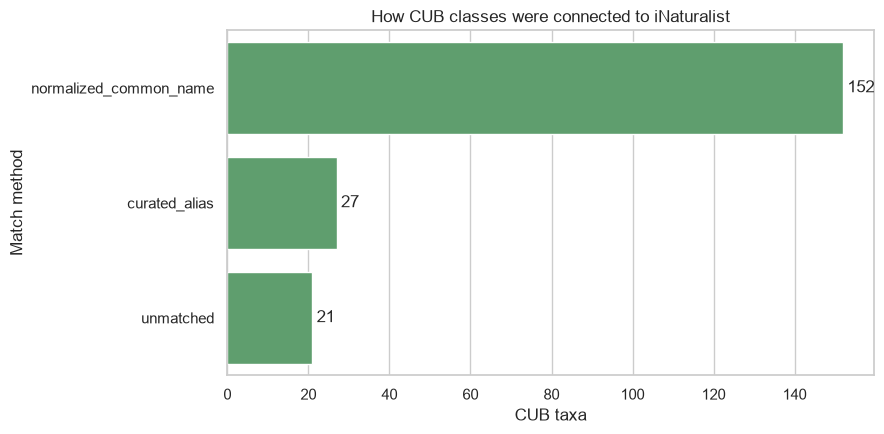

In [8]:
match_method_table = pd.crosstab(
    crosswalk["match_status"], crosswalk["match_method"], margins=True
)
display(match_method_table)

cub_crosswalk = crosswalk[crosswalk["cub_class_id"].notna()].copy()
method_counts = cub_crosswalk["match_method"].value_counts().rename_axis("match_method").reset_index(name="CUB taxa")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=method_counts, y="match_method", x="CUB taxa", ax=ax, color="#55a868")
ax.set(title="How CUB classes were connected to iNaturalist", xlabel="CUB taxa", ylabel="Match method")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

### CUB-only and curated matches

`cub_only` rows are the CUB classes without an iNaturalist counterpart in this bridge. Curated aliases deserve separate review because they were matched through an explicit mapping rather than normalized common-name equality.

In [9]:
review_columns = [
    "cub_class_id", "cub_common_name", "cub_image_count", "inaturalist_category_id",
    "inaturalist_common_name", "inaturalist_image_count", "match_method", "match_note",
]
display(Markdown("#### Unmatched CUB classes"))
display(
    cub_crosswalk.loc[cub_crosswalk["match_status"].eq("cub_only"), review_columns]
    .sort_values("cub_class_id")
    .reset_index(drop=True)
)
display(Markdown("#### Curated alias matches"))
display(
    cub_crosswalk.loc[cub_crosswalk["match_method"].eq("curated_alias"), review_columns]
    .sort_values("cub_class_id")
    .reset_index(drop=True)
)

#### Unmatched CUB classes

,cub_class_id,cub_common_name,cub_image_count,inaturalist_category_id,inaturalist_common_name,inaturalist_image_count,match_method,match_note
0,3.000,Sooty Albatross,58,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
1,5.000,Crested Auklet,44,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
2,6.000,Least Auklet,41,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
3,7.000,Parakeet Auklet,53,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
4,18.000,Spotted Catbird,45,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
5,22.000,Chuck will Widow,56,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
6,24.000,Red faced Cormorant,52,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
7,32.000,Mangrove Cuckoo,53,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
8,63.000,Ivory Gull,60,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...
9,65.000,Slaty backed Gull,50,NaN,NaN,0,unmatched,No corresponding category in the iNaturalist m...


#### Curated alias matches

,cub_class_id,cub_common_name,cub_image_count,inaturalist_category_id,inaturalist_common_name,inaturalist_image_count,match_method,match_note
0,9.000,Brewer Blackbird,59,"3,875.000",Brewer's Blackbird,50,curated_alias,Brewer Blackbird = Brewer's Blackbird
1,17.000,Cardinal,57,"3,709.000",Northern Cardinal,50,curated_alias,Cardinal = Northern Cardinal
2,23.000,Brandt Cormorant,59,"4,579.000",Brandt's Cormorant,50,curated_alias,Brandt Cormorant = Brandt's Cormorant
3,44.000,Frigatebird,60,"4,568.000",Magnificent Frigatebird,50,curated_alias,Frigatebird = Magnificent Frigatebird
4,48.000,European Goldfinch,60,"3,809.000",Eurasian Goldfinch,50,curated_alias,European Goldfinch = Eurasian Goldfinch
5,61.000,Heermann Gull,60,"3,419.000",Heermann's Gull,50,curated_alias,Heermann Gull = Heermann's Gull
6,67.000,Anna Hummingbird,60,"3,310.000",Anna's Hummingbird,50,curated_alias,Anna Hummingbird = Anna's Hummingbird
7,74.000,Florida Jay,60,"3,742.000",Florida Scrub Jay,50,curated_alias,Florida Jay = Florida Scrub Jay
8,83.000,White breasted Kingfisher,60,"3,556.000",White-throated Kingfisher,50,curated_alias,White breasted Kingfisher = White-throated Kin...
9,91.000,Mockingbird,60,"3,944.000",Northern Mockingbird,50,curated_alias,Mockingbird = Northern Mockingbird


## 5. Taxon and class balance

,cub_common_name,inaturalist_common_name,cub_image_count,inaturalist_image_count,combined_image_count,inat_to_cub_ratio,match_method
28,American Crow,American Crow,60,50,110,0.833,normalized_common_name
46,American Goldfinch,American Goldfinch,60,50,110,0.833,normalized_common_name
103,American Pipit,American Pipit,60,50,110,0.833,normalized_common_name
108,American Redstart,American Redstart,60,50,110,0.833,normalized_common_name
66,Anna Hummingbird,Anna's Hummingbird,60,50,110,0.833,curated_alias
94,Baltimore Oriole,Baltimore Oriole,60,50,110,0.833,normalized_common_name
135,Barn Swallow,Barn Swallow,60,50,110,0.833,normalized_common_name
157,Bay breasted Warbler,Bay-breasted Warbler,60,50,110,0.833,normalized_common_name
78,Belted Kingfisher,Belted Kingfisher,60,50,110,0.833,normalized_common_name
192,Bewick Wren,Bewick's Wren,60,50,110,0.833,curated_alias


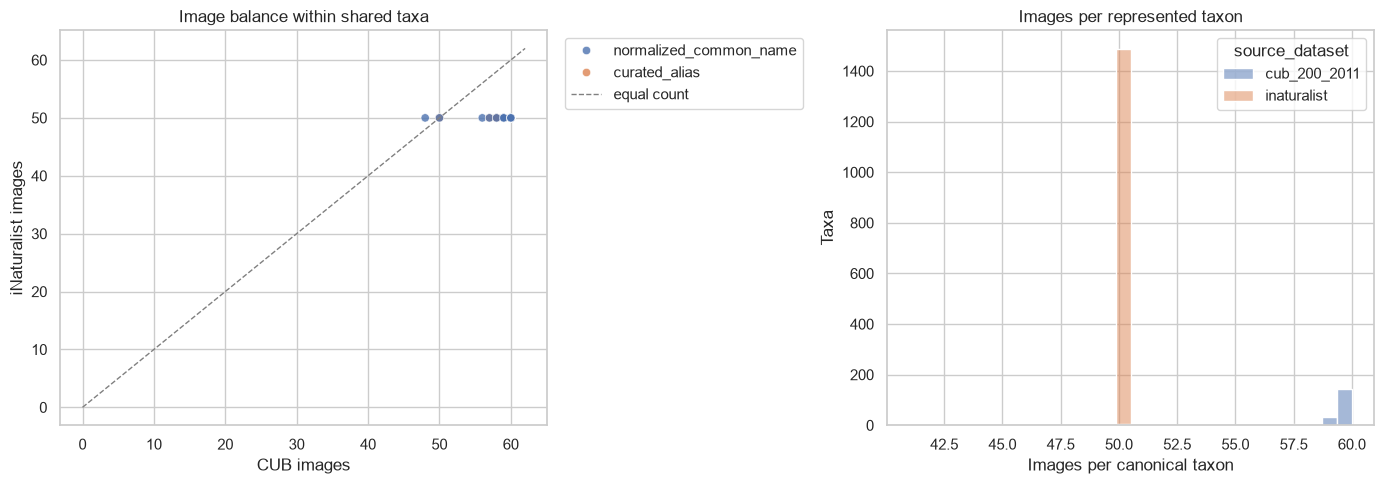

In [10]:
shared = crosswalk[crosswalk["match_status"].eq("shared_taxon")].copy()
shared["combined_image_count"] = shared["cub_image_count"] + shared["inaturalist_image_count"]
shared["inat_to_cub_ratio"] = shared["inaturalist_image_count"] / shared["cub_image_count"]

display(
    shared[[
        "cub_common_name", "inaturalist_common_name", "cub_image_count",
        "inaturalist_image_count", "combined_image_count", "inat_to_cub_ratio", "match_method",
    ]]
    .sort_values(["combined_image_count", "cub_common_name"], ascending=[False, True])
    .head(20)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=shared, x="cub_image_count", y="inaturalist_image_count",
    hue="match_method", alpha=0.8, ax=axes[0],
)
limit = max(shared["cub_image_count"].max(), shared["inaturalist_image_count"].max()) + 2
axes[0].plot([0, limit], [0, limit], "--", color="gray", linewidth=1, label="equal count")
axes[0].set(title="Image balance within shared taxa", xlabel="CUB images", ylabel="iNaturalist images")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

images_per_taxon = manifest.groupby(["source_dataset", "canonical_taxon_id"], observed=True).size().reset_index(name="images")
sns.histplot(data=images_per_taxon, x="images", hue="source_dataset", multiple="layer", bins=30, ax=axes[1])
axes[1].set(title="Images per represented taxon", xlabel="Images per canonical taxon", ylabel="Taxa")
plt.tight_layout()
plt.show()

In [11]:
balance_summary = (
    manifest.groupby(["source_dataset", "canonical_taxon_id"], observed=True)
    .size()
    .groupby(level=0)
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
)
display(balance_summary)

largest_taxa = (
    manifest.groupby(["canonical_taxon_id", "common_name", "source_dataset"], observed=True)
    .size()
    .reset_index(name="images")
    .sort_values("images", ascending=False)
    .head(20)
)
display(largest_taxa.reset_index(drop=True))

,count,mean,std,min,5%,25%,50%,75%,95%,max
source_dataset,,,,,,,,,,
cub_200_2011,200.000,58.940,2.919,41.000,51.950,59.000,60.000,60.000,60.000,60.000
inaturalist,"1,486.000",50.000,0.000,50.000,50.000,50.000,50.000,50.000,50.000,50.000


,canonical_taxon_id,common_name,source_dataset,images
0,cub:103,Sayornis,cub_200_2011,60
1,cub:72,Pomarine Jaeger,cub_200_2011,60
2,cub:71,Long tailed Jaeger,cub_200_2011,60
3,cub:63,Ivory Gull,cub_200_2011,60
4,cub:70,Green Violetear,cub_200_2011,60
5,inaturalist:4487,Black-footed Albatross,cub_200_2011,60
6,inaturalist:4493,Northern Fulmar,cub_200_2011,60
7,inaturalist:4568,Magnificent Frigatebird,cub_200_2011,60
8,inaturalist:4452,Red-headed Woodpecker,cub_200_2011,60
9,inaturalist:4474,Western Grebe,cub_200_2011,60


## 6. Taxonomic composition

,manifest_cub_200_2011,manifest_inaturalist,crosswalk_unique_including_missing
order,13,32,33
family,36,147,148
genus,113,648,649
scientific_name,180,1486,1487


source_dataset,cub_200_2011,inaturalist,total
order,,,
Passeriformes,7578,33900,41478
Charadriiformes,883,8200,9083
Anseriformes,240,4600,4840
Accipitriformes,0,3800,3800
Pelecaniformes,110,3050,3160
Piciformes,408,2650,3058
Caprimulgiformes,240,2200,2440
Psittaciformes,0,2050,2050
Coraciiformes,300,1550,1850


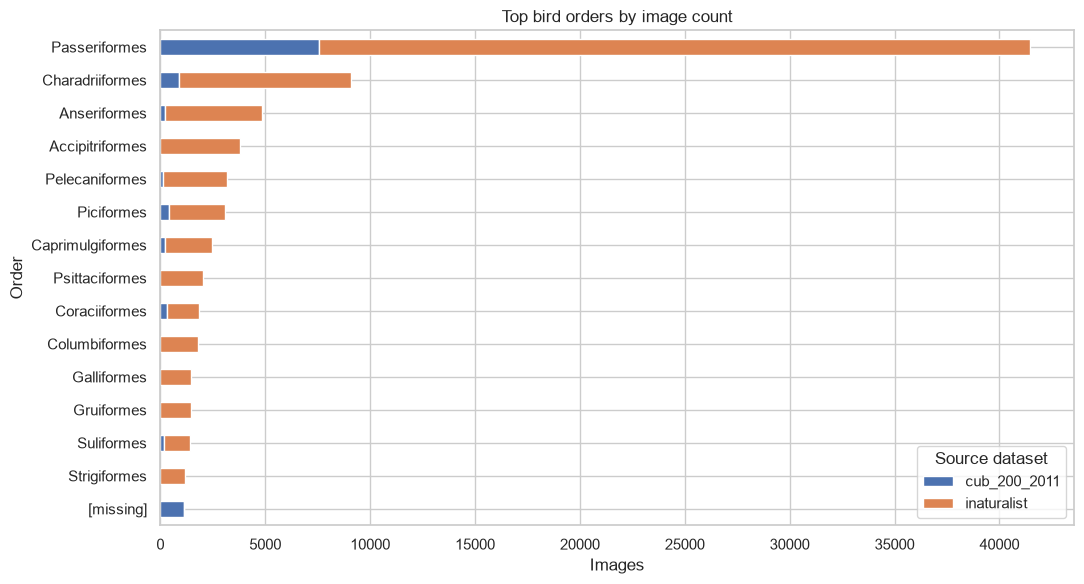

In [12]:
taxonomy_levels = ["order", "family", "genus", "scientific_name"]
taxonomy_diversity = manifest.groupby("source_dataset", observed=True)[taxonomy_levels].nunique(dropna=False).T
taxonomy_diversity.columns = [f"manifest_{column}" for column in taxonomy_diversity.columns]
taxonomy_diversity["crosswalk_unique_including_missing"] = crosswalk[taxonomy_levels].nunique(dropna=False)
display(taxonomy_diversity)

order_images = (
    manifest.assign(order=manifest["order"].fillna("[missing]"))
    .groupby(["order", "source_dataset"], observed=True)
    .size()
    .unstack(fill_value=0)
)
order_images["total"] = order_images.sum(axis=1)
top_orders = order_images.nlargest(15, "total").drop(columns="total")
display(top_orders.assign(total=top_orders.sum(axis=1)))

top_orders.plot(kind="barh", stacked=True, figsize=(11, 6), color=["#4c72b0", "#dd8452"])
plt.gca().invert_yaxis()
plt.title("Top bird orders by image count")
plt.xlabel("Images")
plt.ylabel("Order")
plt.legend(title="Source dataset")
plt.tight_layout()
plt.show()

## 7. Image dimensions and storage

source_dataset         cub_200_2011  inaturalist
width_px        count    11,788.000   74,300.000
                mean        467.887      478.398
                std          63.930       52.666
                min         121.000       61.000
                1%          244.000      281.000
                25%         495.000      500.000
                50%         500.000      500.000
                75%         500.000      500.000
                99%         500.000      500.000
                max         500.000      500.000
height_px       count    11,788.000   74,300.000
                mean        386.030      382.027
                std          70.890       67.043
                min         120.000       67.000
                1%          221.000      251.000
                25%         333.000      333.000
                50%         375.000      375.000
                75%         434.000      400.000
                99%         500.000      500.000
                max         500.000      500.000
megapixels      count    11,788.000        0.000
                mean          0.179          NaN
                std           0.032          NaN
                min           0.019          NaN
                1%            0.059          NaN
                25%           0.167          NaN
                50%           0.178          NaN
                75%           0.194          NaN
                99%           0.250          NaN
                max           0.250          NaN
aspect_ratio    count    11,788.000        0.000
                mean          1.257          NaN
                std           0.289          NaN
                min           0.375          NaN
                1%            0.662          NaN
                25%           1.081          NaN
                50%           1.333          NaN
                75%           1.497          NaN
                99%           1.761          NaN
                max           3.597          NaN
file_size_bytes count    11,788.000   74,300.000
                mean     97,612.023   74,130.700
                std      43,338.983   31,161.476
                min       2,621.000    2,774.000
                1%       13,070.950   15,566.950
                25%      69,773.750   51,453.750
                50%      93,874.000   71,577.000
                75%     121,530.250   94,314.250
                99%     222,070.170  152,694.060
                max     366,826.000  227,473.000

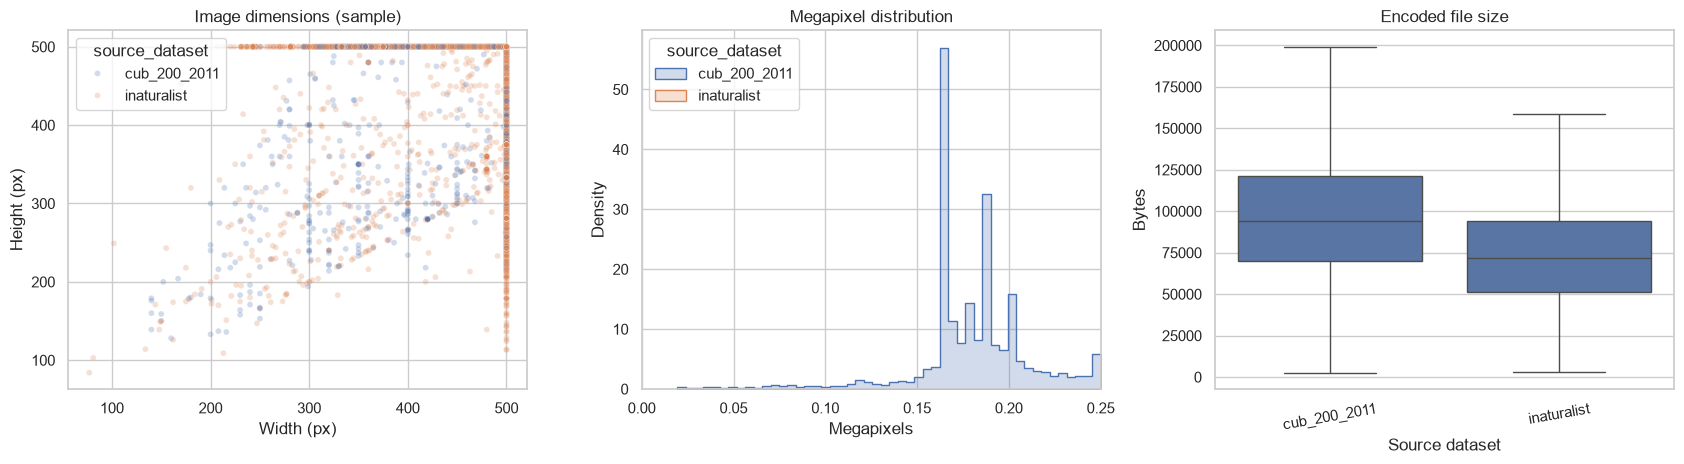

In [13]:
image_metrics = ["width_px", "height_px", "megapixels", "aspect_ratio", "file_size_bytes"]
metric_summary = manifest.groupby("source_dataset", observed=True)[image_metrics].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]
).T
display(metric_summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sample = manifest.sample(min(30_000, len(manifest)), random_state=42)
sns.scatterplot(data=sample, x="width_px", y="height_px", hue="source_dataset", alpha=0.25, s=18, ax=axes[0])
axes[0].set(title="Image dimensions (sample)", xlabel="Width (px)", ylabel="Height (px)")
sns.histplot(data=manifest, x="megapixels", hue="source_dataset", bins=50, element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set(title="Megapixel distribution", xlabel="Megapixels", xlim=(0, manifest["megapixels"].quantile(0.995)))
sns.boxplot(data=manifest, x="source_dataset", y="file_size_bytes", showfliers=False, ax=axes[2])
axes[2].set(title="Encoded file size", xlabel="Source dataset", ylabel="Bytes")
axes[2].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

In [14]:
display(Markdown("### Orientation by source"))
display(pd.crosstab(manifest["orientation"].fillna("[missing]"), manifest["source_dataset"], margins=True))

total_storage_gib = manifest.groupby("source_dataset", observed=True)["file_size_bytes"].sum() / 1024**3
display(total_storage_gib.rename("total_encoded_GiB").to_frame())

### Orientation by source

source_dataset,cub_200_2011,inaturalist,All
orientation,,,
[missing],0,74300,74300
landscape,9156,0,9156
portrait,2374,0,2374
square,258,0,258
All,11788,74300,86088


,total_encoded_GiB
source_dataset,
cub_200_2011,1.072
inaturalist,5.130


## 8. CUB-specific EDA: split, boxes, and annotations

match_status,cub_only,shared_taxon,All
split,,,
test,501,5293,5794
train,630,5364,5994
All,1131,10657,11788


,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,max
bbox_area_fraction,"11,788.000",0.346,0.176,0.050,0.081,0.139,0.207,0.317,0.454,0.592,0.832,1.000
visible_part_count,"11,788.000",11.996,1.320,3.000,8.000,10.000,11.000,12.000,13.000,13.000,14.000,15.000
present_attribute_count,"11,788.000",31.477,8.483,3.000,6.000,23.000,27.000,31.000,36.000,42.000,56.000,72.000


,passed
split populated,True
is_training_image agrees with split,True
all bounding boxes within image,False
"bounding-box area fraction in (0, 1]",True


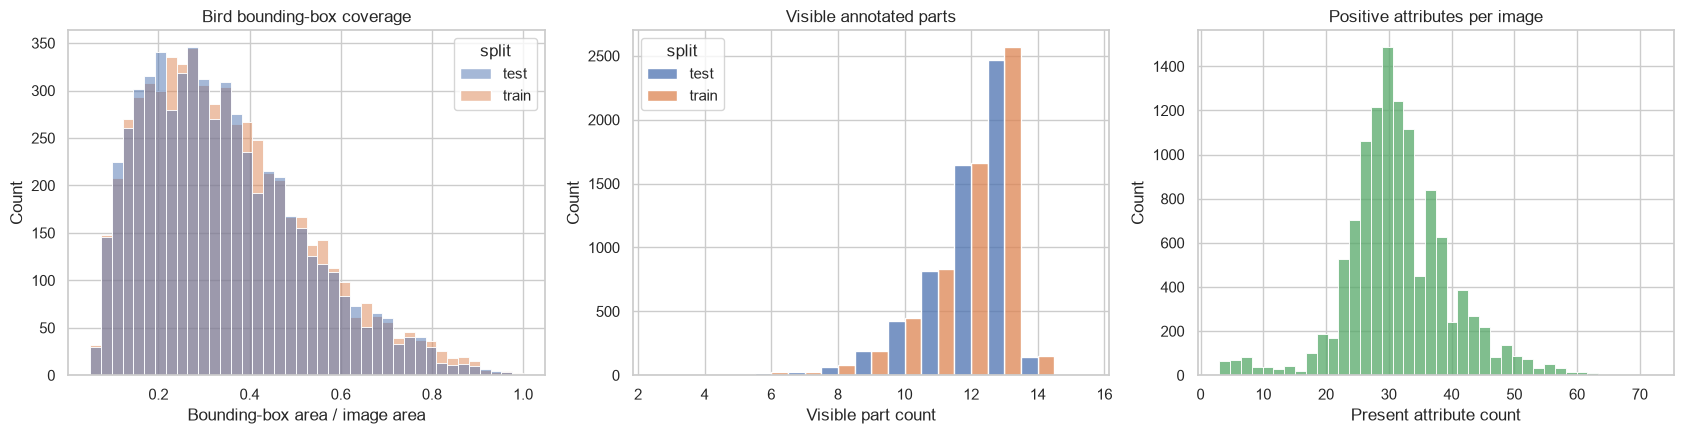

In [15]:
cub = manifest[manifest["source_dataset"].eq("cub_200_2011")].copy()

split_summary = pd.crosstab(cub["split"], cub["match_status"], margins=True)
bbox_summary = cub[["bbox_area_fraction", "visible_part_count", "present_attribute_count"]].describe(
    percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]
).T
display(split_summary)
display(bbox_summary)

cub_checks = pd.Series(
    {
        "split populated": cub["split"].notna().all(),
        "is_training_image agrees with split": cub["is_training_image"].eq(cub["split"].eq("train").astype(float)).all(),
        "all bounding boxes within image": cub["bbox_within_image"].fillna(False).astype(bool).all(),
        "bounding-box area fraction in (0, 1]": cub["bbox_area_fraction"].between(0, 1, inclusive="right").all(),
    }, name="passed"
).to_frame()
display(cub_checks)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(data=cub, x="bbox_area_fraction", hue="split", bins=40, ax=axes[0])
axes[0].set(title="Bird bounding-box coverage", xlabel="Bounding-box area / image area")
sns.histplot(data=cub, x="visible_part_count", hue="split", discrete=True, multiple="dodge", ax=axes[1])
axes[1].set(title="Visible annotated parts", xlabel="Visible part count")
sns.histplot(data=cub, x="present_attribute_count", bins=40, ax=axes[2], color="#55a868")
axes[2].set(title="Positive attributes per image", xlabel="Present attribute count")
plt.tight_layout()
plt.show()

In [16]:
cub_class_split = (
    cub.groupby(["cub_class_id", "common_name", "split"], observed=True)
    .size()
    .unstack(fill_value=0)
)
for split in ["train", "test"]:
    if split not in cub_class_split:
        cub_class_split[split] = 0
cub_class_split["total"] = cub_class_split[["train", "test"]].sum(axis=1)
cub_class_split["train_fraction"] = cub_class_split["train"] / cub_class_split["total"]
display(cub_class_split.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]))
display(cub_class_split.sort_values("train_fraction").head(10))

split,test,train,total,train_fraction
count,200.000,200.000,200.000,200.000
mean,28.970,29.970,58.940,0.510
std,2.921,0.171,2.919,0.032
min,11.000,29.000,41.000,0.492
1%,14.990,29.000,44.990,0.492
25%,29.000,30.000,59.000,0.500
50%,30.000,30.000,60.000,0.500
75%,30.000,30.000,60.000,0.502
99%,30.000,30.000,60.000,0.667
max,30.000,30.000,60.000,0.732


,split,test,train,total,train_fraction
cub_class_id,common_name,,,,
107.000,Common Raven,30,29,59,0.492
126.000,Nelson's Sharp-tailed Sparrow,30,29,59,0.492
196.000,House Wren,30,29,59,0.492
135.000,Bank Swallow,30,29,59,0.492
13.000,Bobolink,30,30,60,0.500
14.000,Indigo Bunting,30,30,60,0.500
1.000,Black-footed Albatross,30,30,60,0.500
2.000,Laysan Albatross,30,30,60,0.500
31.000,Black-billed Cuckoo,30,30,60,0.500


## 9. iNaturalist-specific EDA: time, geography, and licensing

In [17]:
inat = manifest[manifest["source_dataset"].eq("inaturalist")].copy()

inat_coverage_fields = [
    "date_parsed", "rights_holder", "latitude", "longitude", "location_uncertainty",
    "license_id", "license_name", "scientific_name", "order", "family", "genus",
]
inat_coverage = pd.DataFrame(
    {
        "non_null": inat[inat_coverage_fields].notna().sum(),
        "coverage_pct": inat[inat_coverage_fields].notna().mean() * 100,
    }
).sort_values("coverage_pct")
display(inat_coverage.style.format({"non_null": "{:,.0f}", "coverage_pct": "{:.1f}%"}).background_gradient(subset=["coverage_pct"], cmap="Blues"))

geo_checks = pd.Series(
    {
        "non-null latitudes are valid": inat["latitude"].dropna().between(-90, 90).all(),
        "non-null longitudes are valid": inat["longitude"].dropna().between(-180, 180).all(),
        "non-null uncertainty is non-negative": inat["location_uncertainty"].dropna().ge(0).all(),
    }, name="passed"
).to_frame()
display(geo_checks)

,non_null,coverage_pct
location_uncertainty,"62,775",84.5%
longitude,"74,130",99.8%
latitude,"74,130",99.8%
rights_holder,"74,300",100.0%
date_parsed,"74,300",100.0%
license_id,"74,300",100.0%
license_name,"74,300",100.0%
scientific_name,"74,300",100.0%
order,"74,300",100.0%
family,"74,300",100.0%


,passed
non-null latitudes are valid,True
non-null longitudes are valid,True
non-null uncertainty is non-negative,True


,license,images
0,Attribution-NonCommercial License,66830
1,Attribution License,3275
2,Attribution-NonCommercial-NoDerivatives License,1656
3,Attribution-NonCommercial-ShareAlike License,1057
4,Public Domain Dedication,824
5,Attribution-ShareAlike License,519
6,Attribution-NoDerivatives License,139


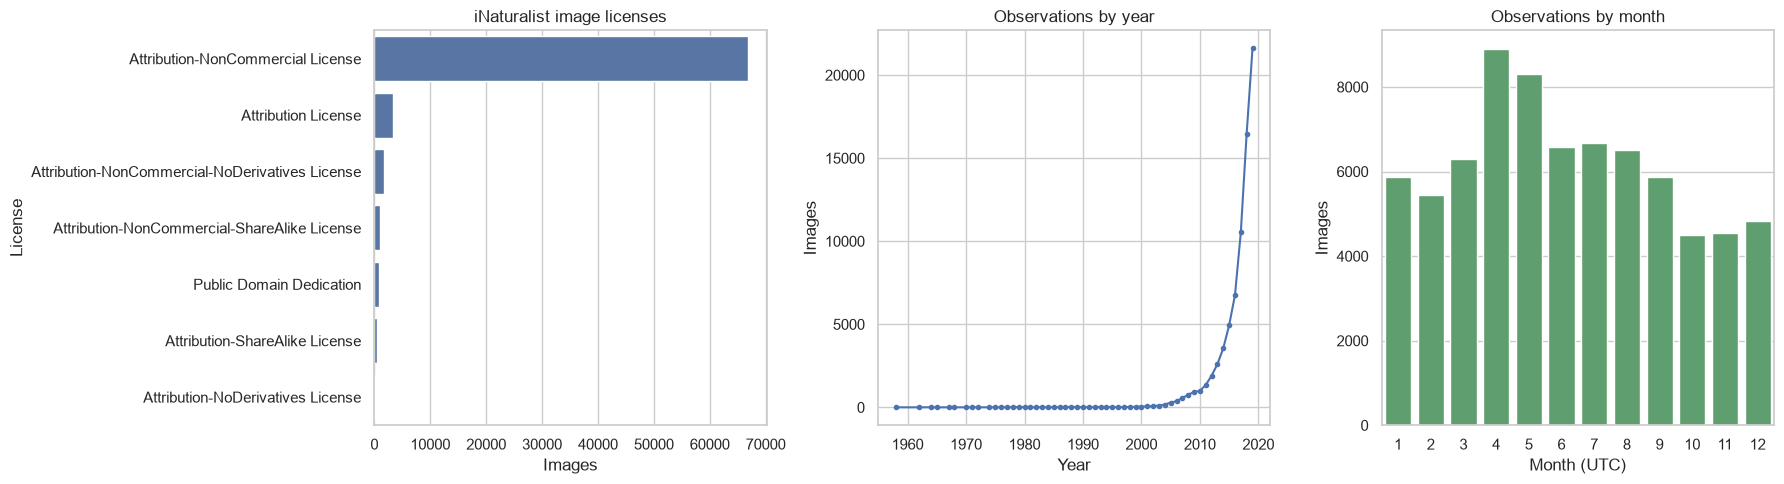

In [18]:
license_counts = inat["license_name"].fillna("[missing]").value_counts().rename_axis("license").reset_index(name="images")
display(license_counts)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=license_counts, y="license", x="images", color="#4c72b0", ax=axes[0])
axes[0].set(title="iNaturalist image licenses", xlabel="Images", ylabel="License")

dated = inat.dropna(subset=["date_parsed"]).copy()
if not dated.empty:
    dated["year"] = dated["date_parsed"].dt.year
    dated["month"] = dated["date_parsed"].dt.month
    year_counts = dated["year"].value_counts().sort_index()
    axes[1].plot(year_counts.index, year_counts.values, marker="o", markersize=3)
    axes[1].set(title="Observations by year", xlabel="Year", ylabel="Images")
    sns.countplot(data=dated, x="month", color="#55a868", ax=axes[2])
    axes[2].set(title="Observations by month", xlabel="Month (UTC)", ylabel="Images")
else:
    axes[1].text(0.5, 0.5, "No parseable dates", ha="center", va="center")
    axes[2].text(0.5, 0.5, "No parseable dates", ha="center", va="center")
plt.tight_layout()
plt.show()

Geocoded iNaturalist images: 74,130 / 74,300 (99.8%)


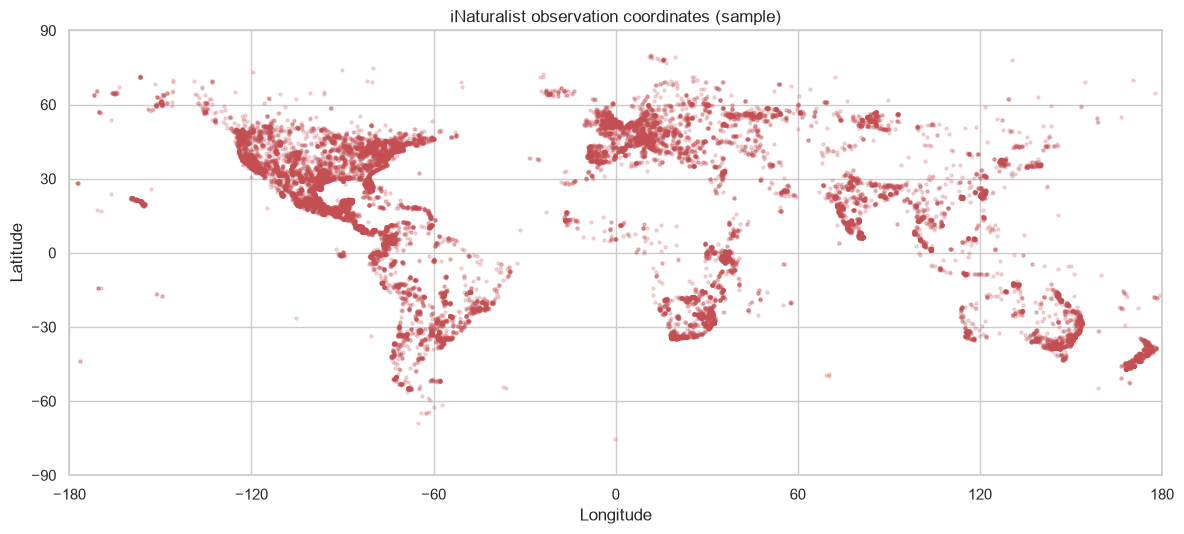

In [19]:
geocoded = inat.dropna(subset=["latitude", "longitude"])
print(f"Geocoded iNaturalist images: {len(geocoded):,} / {len(inat):,} ({len(geocoded) / len(inat):.1%})")

if not geocoded.empty:
    plot_geo = geocoded.sample(min(30_000, len(geocoded)), random_state=42)
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.scatter(plot_geo["longitude"], plot_geo["latitude"], s=5, alpha=0.2, color="#c44e52")
    ax.set(xlim=(-180, 180), ylim=(-90, 90), xlabel="Longitude", ylabel="Latitude", title="iNaturalist observation coordinates (sample)")
    ax.set_xticks(np.arange(-180, 181, 60))
    ax.set_yticks(np.arange(-90, 91, 30))
    plt.tight_layout()
    plt.show()

## 10. Consolidated findings

In [20]:
status_counts = crosswalk["match_status"].value_counts()
source_counts = manifest["source_dataset"].value_counts()
failed_checks = quality_checks.index[~quality_checks["passed"]].tolist()
unmatched_cub = int((cub_crosswalk["match_status"] == "cub_only").sum())
shared_taxa = int((crosswalk["match_status"] == "shared_taxon").sum())
curated_matches = int((cub_crosswalk["match_method"] == "curated_alias").sum())

findings = f'''
### Automated summary

- The manifest contains **{len(manifest):,} images**: **{source_counts.get('cub_200_2011', 0):,} CUB** and **{source_counts.get('inaturalist', 0):,} iNaturalist**.
- The crosswalk contains **{len(crosswalk):,} canonical taxa**: **{shared_taxa:,} shared**, **{status_counts.get('cub_only', 0):,} CUB-only**, and **{status_counts.get('inaturalist_only', 0):,} iNaturalist-only**.
- Of the CUB classes, **{curated_matches:,}** use curated aliases and **{unmatched_cub:,}** have no mapped iNaturalist category.
- Shared taxa contribute **{int(manifest['shared_between_datasets'].sum()):,} image rows** across both sources.
- The manifest references **{manifest['file_size_bytes'].sum() / 1024**3:,.2f} GiB** of encoded image files.
- Crosswalk count audit mismatches: **{int((~count_audit['cub_count_agrees']).sum())} CUB** and **{int((~count_audit['inaturalist_count_agrees']).sum())} iNaturalist** taxa.
- Core quality checks failing: **{len(failed_checks)}** ({', '.join(failed_checks) if failed_checks else 'none'}).

### Modeling considerations

- Split by a stable grouping key (for example, canonical taxon and/or observation grouping) rather than random image rows when leakage is a concern.
- Treat source-specific nulls as not-applicable, not automatically as data-quality failures.
- Account for dataset/source imbalance and the difference between shared versus source-only taxa when defining the prediction task.
- Review the CUB-only and curated-alias tables above before treating all crosswalk relationships as taxonomically interchangeable.
- Check license constraints before redistribution or deployment involving iNaturalist imagery.
'''
display(Markdown(findings))


### Automated summary

- The manifest contains **86,088 images**: **11,788 CUB** and **74,300 iNaturalist**.
- The crosswalk contains **1,507 canonical taxa**: **179 shared**, **21 CUB-only**, and **1,307 iNaturalist-only**.
- Of the CUB classes, **27** use curated aliases and **21** have no mapped iNaturalist category.
- Shared taxa contribute **19,607 image rows** across both sources.
- The manifest references **6.20 GiB** of encoded image files.
- Crosswalk count audit mismatches: **0 CUB** and **0 iNaturalist** taxa.
- Core quality checks failing: **0** (none).

### Modeling considerations

- Split by a stable grouping key (for example, canonical taxon and/or observation grouping) rather than random image rows when leakage is a concern.
- Treat source-specific nulls as not-applicable, not automatically as data-quality failures.
- Account for dataset/source imbalance and the difference between shared versus source-only taxa when defining the prediction task.
- Review the CUB-only and curated-alias tables above before treating all crosswalk relationships as taxonomically interchangeable.
- Check license constraints before redistribution or deployment involving iNaturalist imagery.
